# Custom Multi-Chain Metropolis-Hastings MCMC Sampler and Diagnostic Framework for Bayesian Logistic Regression

***

**Author:** Daniel Therattil  

**Methodology:** Custom Metropolis-Hastings MCMC(Markov Chain Monte Carlo) Sampler | Gaussian Priors & Log-Posterior Derivations | Multi-Chain Initialization | Bayesian Logistic Regression 

**Key Validation Metrics:**  Gelman-Rubin: $\hat{R} \lt 1.01$ | Rank-Normalized Multi-Chain Split: $\hat{R} \lt 1.01$ | Bulk ESS: $\gt 400$ | Tail ESS: $\gt 400$

### Abstract & Methodological Overview
This project is an implementation of a Bayesian Logistic Regression framework built from scratch to evaluate clinical dementia risk using the OASIS Longitudinal cohort. I built it without statistical high-level wrappers (PyMC, Stan, or scikit-learn), the inference engine relies on a custom Metropolis-Hastings Markov Chain Monte Carlo (MCMC) sampler written in NumPy matrix algebra.

#### Key Statistical Methods and Results:
**Prior Specification & Joint Log-Posterior Formulation:** Evaluated uninformative Gaussian priors across standardized biomarkers and derived the unnormalized log-posterior distribution via matrix vectorization. Handled floating-point numerical stability using log-sum-exp transformations to prevent burgeoning or computational overflow during likelihood calculations.\
\
**Multi-Chain Parallel Sampling Engine:** Deployed parallel Markov chains initialized from dispersed random starting points to thoroughly explore the parameter space over 125,000 post-burn-in Monte Carlo draws.\
\
**Single/Multi-Chain MCMC Convergence Diagnostics:** Evaluated stationarity and mixing efficiency via Gelman-Rubin, Blom's quantile-transformed Rank-Normalized Split, and Charles Geyer's Integrated Autocorrelation Time (IAT) method for Bulk and Tail Effective Sample Sizes.\
\
**Clinical Parameter Results:** Quantified epistemic uncertainty through 95% Credible Intervals and Posterior Odds Ratios, identifying Mini-Mental State Examination (MMSE) and Normalized Whole Brain Volume (nWBV) as the primary protective biomarkers against dementia progression.

***

## Importing Libraries/Packages:

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pymc as pm
from scipy.stats import norm, rankdata

In [7]:
df = pd.read_csv("oasis_longitudinal.csv")
df.head()

,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


Each of the possible predictors are MR delay time, dominant hand type, age, years of education, socioeconomic status, mini mental state examination, clinical dementia rating, estimated total intracranial volume, normalize whole brain volume, and atlas scaling factor.

## Data Cleaning:

In [8]:
df_baseline = df[df['Visit'] == 1].copy()
print("Cohort Shape:", df_baseline.shape)
print("Missing Values per Column:\n", df_baseline.isna().sum())

Cohort Shape: (150, 15)
Missing Values per Column:
 Subject ID    0
MRI ID        0
Group         0
Visit         0
MR Delay      0
M/F           0
Hand          0
Age           0
EDUC          0
SES           8
MMSE          0
CDR           0
eTIV          0
nWBV          0
ASF           0
dtype: int64


So based off the shape of the data, there are 150 unique patients within the dataset and 8 values missing within the SES column that we must account and clean from the dataset. Chose to look at them as 1 visit each since it eliminates confounding time-dependent factors such as learning effects on cognitive tests or progressive disease stages. 

In [9]:
df_model = df_baseline.dropna(subset = ['SES']).copy() #Since 8 values missing only in the SES, dropped specifically from the column using this.
df_model['CDR'].value_counts()

CDR
0.0    85
0.5    44
1.0    13
Name: count, dtype: int64

Based off the Clinical Dementia Rating(CDR), around 85 patients are perfectly fine while 57 display some level of dementia progression with 0.5 signifying a very mild dementia and 1.0 corresponding to mild dementia. 

## Markov Chain Monte Carlo(MCMC) Single Chain:

In [10]:
df_model['y'] = (df_model['CDR'] > 0).astype(int) #Y is the target variable here.

features = ['Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV'] #These are the predictors for the CDR rating. I had to drop 'ASF' because there was multicollinarity with the eTIV predictor.
X_features = df_model[features]

X_scaled = (X_features - X_features.mean()) / X_features.std() #Standardizing/z-score normalizing the features: Z = (x - μ) / σ

X_scaled.insert(0, 'Intercept', 1.0) #Included an intercept column for the initial/baseline log-odds of dementia for the avg patient in the dataset.

X = X_scaled.values
y = df_model['y'].values

print("Design Matrix X shape:", X.shape) 
print("Target Vector y shape:", y.shape)

Design Matrix X shape: (142, 6)
Target Vector y shape: (142,)


I standardized the features to allow for uniform scaling across predictors. This inturn prevents computational burgeoning in both directions, and allows for consistent proposal step sizes and consistent paramater weightage for MCMC sampling.

In [11]:
def log_prior(beta, prior_std = 10.0):
    return np.sum(norm.logpdf(beta, loc = 0, scale = prior_std))

#loc = 0 makes sure we start with a mean of 0. I also chose a scale of 10 to allow for wide variance.
#Then the norm.logpdf(beta,...) gives the probability density of that normal bell curve at the current parameter guess and taking the log of it. 
#The sum part is due to them being independent events, thus probabilites are added together when in log spaces since log(xy) = log(x) + log(y). 

    
def log_likelihood(beta, X, y):
    logits = X @ beta
    log_like = np.sum(y * logits - np.log1p(np.exp(logits)))
    return log_like

#For likelihood, logits = X @ beta calculates the linear predictor using matrix multiplication to get the log odds, then log_like allows us to pass it through a sigmoid function to get the predicted probability of dementia for each patient. Basically it lets us understand how well the proposed weights match reality.

def log_posterior(beta, X, y):
    return log_prior(beta) + log_likelihood(beta, X, y)

#For posterior, since by Bayes Theorem unnormalized we know Log(Posterior) = Log(Prior) + Log(Likelihood) which inturn gives a final calculation for the sampler later on to make a probability distribution.

beta_test = np.zeros(X.shape[1])

#beta_test establishes the starting baseline score before running the sampler.

print("Test Log-Prior =", log_prior(beta_test))
print("Test Log-Likelihood =", log_likelihood(beta_test, X, y))
print("Test Log-Posterior =", log_posterior(beta_test, X, y))

Test Log-Prior = -19.32914175719231
Test Log-Likelihood = -98.42689963951224
Test Log-Posterior = -117.75604139670455


Calculated the log of each variable of Bayes Theorem(Prior, Likelihood, Posterior) and tested them. Due to them being transformed by logs, the probability closer to 0 indicates a better fit. 

In [12]:
def run_metropolis_hastings(X, y, num_samples = 30000, proposal_std = 0.25, seed = 2):
    np.random.seed(seed)
    num_params = X.shape[1]
    
#Took 30,000 monte carlo simulations with a step size of 0.25(how far each jump is for constructing the Markov Chains), and chose a random number for the seed.
#num_params grabs the # of columns/parameters in X.

    chain = np.zeros((num_samples, num_params))
    beta_current = np.zeros(num_params)
    current_log_post = log_posterior(beta_current, X, y)
    accepted_count = 0
    
#Chain is just the markov chain as 30,000 Monte Carlo Simulations by the 7 columns.
#Beta_current sets the starting chain position at 0 and accepted_count tells us everytime a new step is accepted for the chain, which means p(x') > p(x) => α = 1 etc.

    for i in range(num_samples):
        beta_prop = beta_current + np.random.normal(loc = 0.0, scale = proposal_std, size = num_params)
        prop_log_post = log_posterior(beta_prop, X, y)
        log_alpha = prop_log_post - current_log_post
        
#Takes the current position and adds a random Gaussian noise draw centered at 0 with standard deviation 0.25 across all 7 parameters. This is your Markov Chain step proposal.
#The prop log evaluates each candidate step, and the the log alpha calculates the log ratio of the probabilities.    
        
        if np.log(np.random.uniform(0, 1)) < log_alpha:
            beta_current = beta_prop
            current_log_post = prop_log_post
            accepted_count += 1
            
        chain[i] = beta_current
        
    acceptance_rate = accepted_count / num_samples
    
    print("Sampling has been completed.")
    print(f"Acceptance Rate: {acceptance_rate:.2%}")
    
    return chain

#This evaluates that if the candidate step yields a higher posterior, it is always accepted and if the candidate step yields a lower posterior , it is accepted with probability = α.
#Essentially, acceptances mean the current position changes and if rejected it stays in its current position.
#The acceptance rate is just the accepted count of the total number of samples. The target range is 20-50% so after tweaking the step size from 0.05 to 0.25 I found 0.25 gave a proper percentage within the range.
    
chain = run_metropolis_hastings(X, y, num_samples = 30000, proposal_std = 0.25)


Sampling has been completed.
Acceptance Rate: 35.21%


Having completed the Monte Carlo Markov Chain process using Metropolis-Hastings, and obtaining an acceptance rate within the acceptable range of 20-50%, the burn-in discard process is now needed to remove the first N samples to eliminate bias from initial values. 

In [13]:
burn_in = 5000
burn_chain = chain[burn_in:]

print("Original chain shape:", chain.shape)
print("Clean chain shape (after burn-in):", burn_chain.shape)

Original chain shape: (30000, 6)
Clean chain shape (after burn-in): (25000, 6)


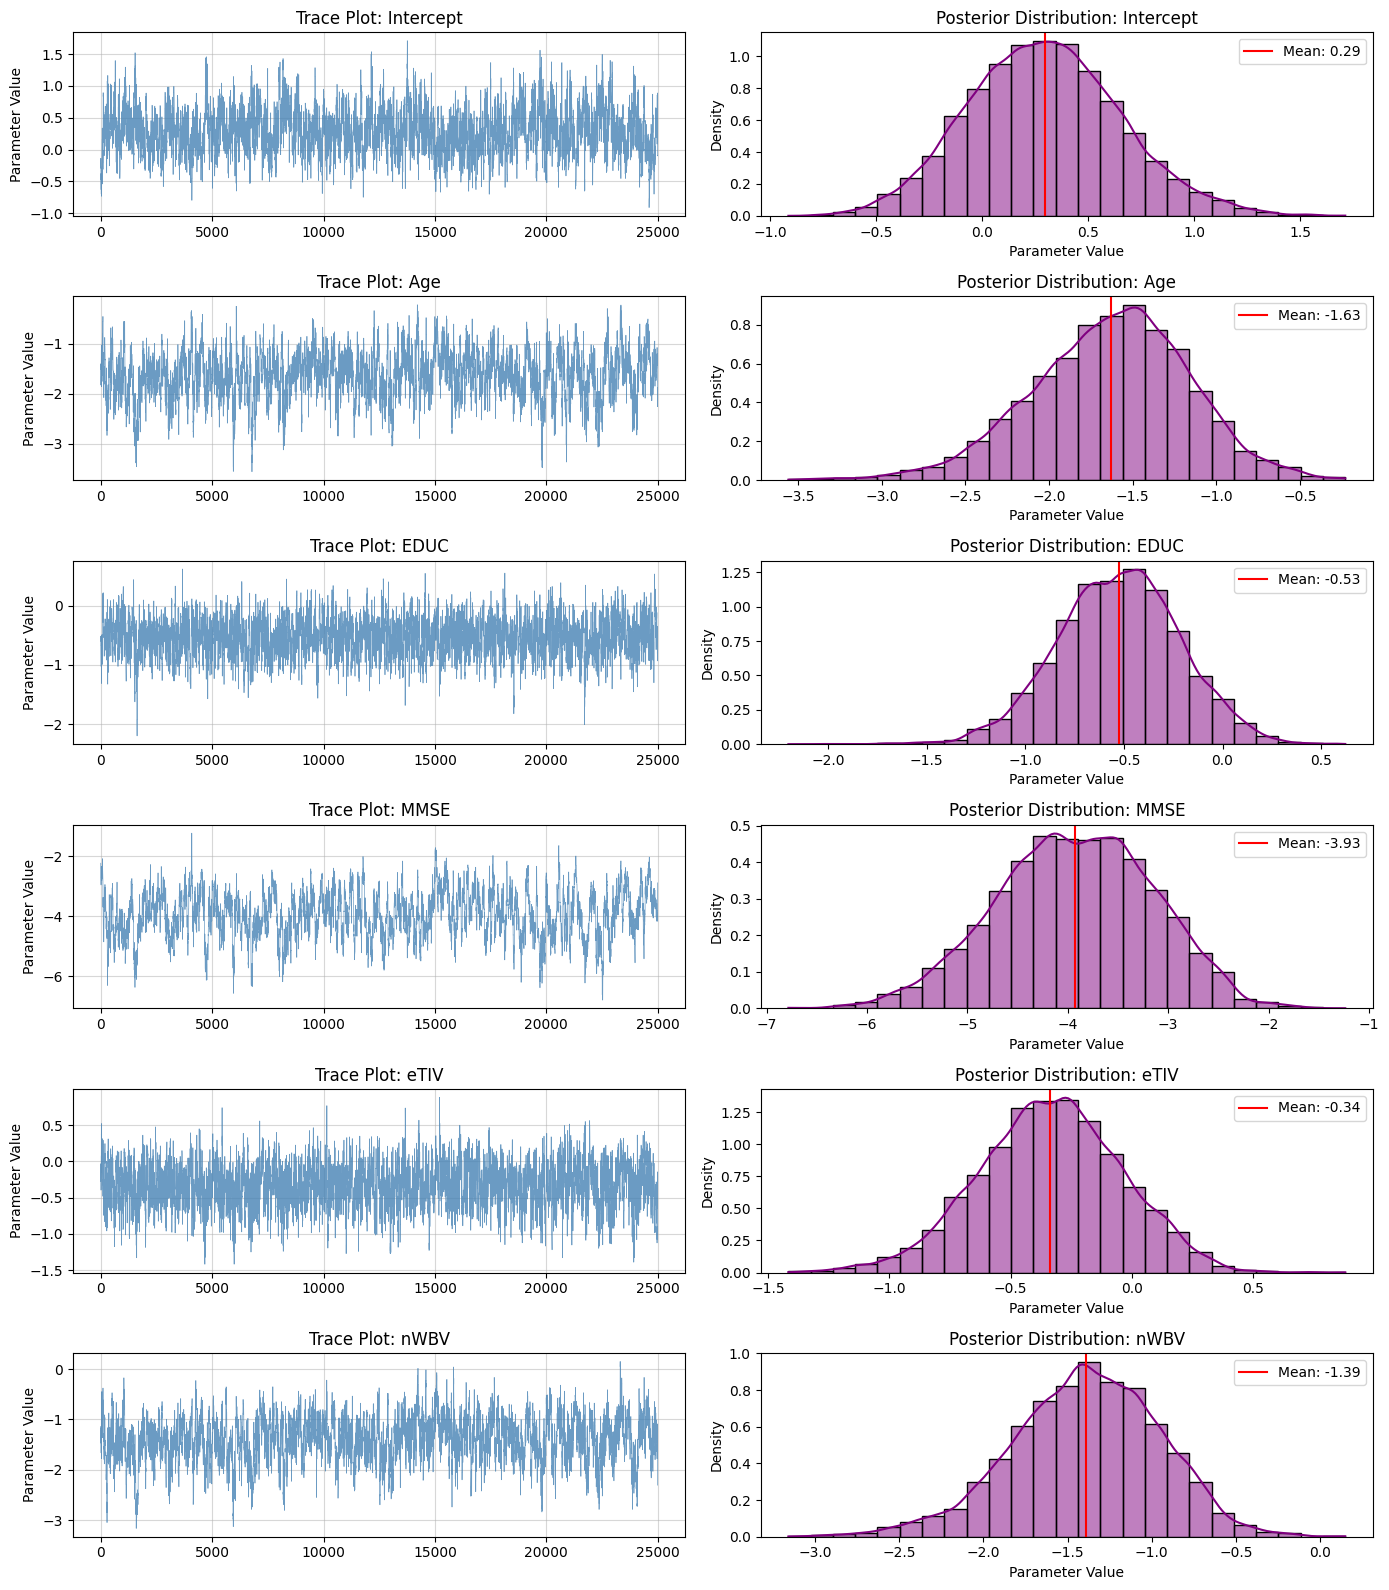

In [14]:
parameter_names = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

fig, axes = plt.subplots(nrows = 6, ncols = 2, figsize = (14, 16))

for i, name in enumerate(parameter_names):
    axes[i, 0].plot(burn_chain[:, i], color = 'steelblue', alpha = 0.8, linewidth = 0.5)
    axes[i, 0].set_title(f'Trace Plot: {name}')
    axes[i, 0].set_ylabel('Parameter Value')
    axes[i, 0].grid(True, linestyle = '-', alpha = 0.5)
#For all 25,000 post burn-in iterations, gives a traceplot for each of the parameters - Left column. The 0 indicates left, whereas 1 indicates right.

    
    sns.histplot(burn_chain[:, i], kde = True, ax = axes[i, 1], color = 'purple', stat = "density", bins = 25) #bins = # of bars on histogram and density makes sure the total area under the curve sums to 1 such that there's a proper probability density scale.
    axes[i, 1].axvline(x = np.mean(burn_chain[:, i]), color = 'red', linestyle = '-', label = f'Mean: {np.mean(burn_chain[:, i]):.2f}')
    axes[i, 1].set_title(f'Posterior Distribution: {name}')
    axes[i, 1].set_xlabel('Parameter Value')
    axes[i, 1].legend()
#For all 25,000 post burn-in iterations, gives a histogram and lays a Kernel Density Estimation over each of them - Right column. 

plt.tight_layout()
plt.show()

After creating traceplots for all my predictors, it is evident that there's a healthy oscillation around a stable level with rapid mixing across the parameter space meaning it follows the healthy fuzzy caterpillar trend needed to say it has convergence and low autocorrelation/reliance on past steps. Now it's important to check if this was a singular lucky chain or if this statistical behavior is consistent throughout multiple chains.

## Markov Chain Monte Carlo(MCMC) Multi-Chain:

In [15]:
def multi_chain(X, y, num_chains = 5, num_samples = 30000, proposal_std = 0.25): #Allows 5 chains to run simultaenously with the same number of samples as the single chain.
    num_params = X.shape[1]
    all_chains = np.zeros((num_chains, num_samples, num_params))
    
    for c in range(num_chains):
        np.random.seed(c + 10)  #Gives a completey distinct seed for each of the chains.
        
        beta_current = np.random.normal(loc = 0.0, scale = 1.0, size = num_params) #Makes sure each chain starts at a randomly dispersed location. 
        current_log_post = log_posterior(beta_current, X, y)
        
        for i in range(num_samples):
            beta_prop = beta_current + np.random.normal(loc = 0.0, scale = proposal_std, size = num_params)
            prop_log_post = log_posterior(beta_prop, X, y)
            log_alpha = prop_log_post - current_log_post
            
            if np.log(np.random.uniform(0, 1)) < log_alpha:
                beta_current = beta_prop
                current_log_post = prop_log_post
                
            all_chains[c, i] = beta_current
            
        print(f"Chain {c+1} finished.")
        
    return all_chains
#It's the same process as before with the singular chain except now every single chain starts at a different position so that we can see if all of them converge to that same distribution or not.

multi_chains = multi_chain(X, y, num_chains = 5, num_samples = 30000, proposal_std = 0.25)

Chain 1 finished.
Chain 2 finished.
Chain 3 finished.
Chain 4 finished.
Chain 5 finished.


Now that all chains have been constructed, it's time to do the burn in just like I did with the singular chain.

In [16]:
burn_in = 5000
clean_multi_chains = multi_chains[:, burn_in:, :]

print("Multi-Chain Array Shape:", multi_chains.shape)  
print("Burn In Multi-Chain Array Shape:", clean_multi_chains.shape) 

Multi-Chain Array Shape: (5, 30000, 6)
Burn In Multi-Chain Array Shape: (5, 25000, 6)


## Single/Multi-Chain Convergence Diagnostics:

### Gelman-Rubin Diagnostic:

In [17]:
import pandas as pd

def compute_gelman_rubin(chains):
    M, N, K = chains.shape
    r_hat_values = []
    
    for k in range(K):
        param_chains = chains[:, :, k]
        
        chain_means = np.mean(param_chains, axis = 1)
        overall_mean = np.mean(chain_means)
        chain_vars = np.var(param_chains, axis = 1, ddof = 1)
        
        B = (N / (M - 1)) * np.sum((chain_means - overall_mean) ** 2) #Gives the variance between the chains.
        
        W = np.mean(chain_vars) #Gives the variance within each of the cahains.
        
        marginal_post_var = ((N - 1) / N) * W + (1 / N) * B #Gives the true marginal posterior variance.
        
        r_hat = np.sqrt(marginal_post_var / W) #Gives the r-hat values >:D !
        r_hat_values.append(r_hat)
        
    return r_hat_values
    
#Gets the matrix for parameter k, mean for each chain, their overall means, between variance(B), and within variance (W), marginal posterior variance, and R-hat for the Gelman-Rubin diagnostic.

r_hats = compute_gelman_rubin(clean_multi_chains)

parameter_names = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

rhat_df = pd.DataFrame({
    'Parameter': parameter_names,
    'Gelman-Rubin (R-hat)': r_hats,
    'Status(Converged < 1.01)': ['Converged' if r < 1.01 else 'Check Convergence' for r in r_hats]
})
#Just made it to display everything in a clean dataframe for easy viewing.

rhat_df

,Parameter,Gelman-Rubin (R-hat),Status(Converged < 1.01)
0,Intercept,1.001682,Converged
1,Age,1.001598,Converged
2,EDUC,1.000443,Converged
3,MMSE,1.002846,Converged
4,eTIV,1.001861,Converged
5,nWBV,1.002345,Converged


Since the Gelman-Rubin Diagnostic assesses whether multiple Markov Chain Monte Carlo chains starting from different initial values converge to the same place if r-hat < 1.01, it is evident here that all the chains for each parameter do and thus allows us to confirm that the chains are in agreement with one another. Now since MCMC draws consecutive steps sequentially, adjacent samples are correlated meaning we need to look at the Effective Sample Size to see how many true independent draws are contained within the 125,000 total post-burn-in draws.

### Effective Sample Size Measures(Bulk and Tail ESS):

#### Bulk ESS

In [18]:
def compute_autocorrelation(chain_1d, max_lag=100):
    n = len(chain_1d)
    mean = np.mean(chain_1d)
    var = np.var(chain_1d)
    
    if var == 0:
        return np.ones(max_lag + 1)
        
    normalized = chain_1d - mean
    acf = np.correlate(normalized, normalized, mode = 'full')[n - 1:] / (var * n)
    return acf[:max_lag + 1]

#Gets the autocorrelation(ρk) so that I could calculate the integrated autocorrelation time for the Bulk ESS. Acf is just the autocorrelated function and I chose the Fast Fourier Transform to compute the dot products in a more efficient manner. 
#The n-1 part makes sure we can disregard the negative lag shifts. 

def compute_bulk_ess(chains_3d):
    M, N, K = chains_3d.shape
    ess_values = []
    
    for k in range(K):
        param_chains = chains_3d[:, :, k]
        
        acfs = np.array([compute_autocorrelation(param_chains[m], max_lag = 1000) for m in range(M)])
        avg_acf = np.mean(acfs, axis = 0)

        positive_sum = 0
        
        for lag in range(1, len(avg_acf) - 1, 2):
            pair_sum = avg_acf[lag] + avg_acf[lag + 1]
            if pair_sum < 0:
                break
            positive_sum += pair_sum
            
        iat = 1 + 2 * positive_sum  
        ess = (M * N) / iat
        ess_values.append(ess)
        
    return ess_values

#Calculates the integrated autocorrelation time(iat) and the ESS, which is just the total burn samples over the iat. 
#Now since the moment a adjacent pair sum drops below zero, it's pure random noise, I used Charles Geyer's method to sum those pairs until they became negative since he shows that they are always strictly decreasing and positive. 

bulk_ess = compute_bulk_ess(clean_multi_chains)

#Computes the Bulk ESS over all the chains I created.

parameter_names = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

ess_df = pd.DataFrame({
    'Parameter': parameter_names,
    'Total Post-Burn Draws': clean_multi_chains.shape[0] * clean_multi_chains.shape[1],
    'Bulk ESS': bulk_ess,
    'Status (> 400)': ['Sufficient Samples' if ess > 400 else 'Requires More Samples' for ess in bulk_ess]
})

ess_df.round(2)

#Now this last part is just a table to display everything and I rounded it to 2 decimal places. 

,Parameter,Total Post-Burn Draws,Bulk ESS,Status (> 400)
0,Intercept,125000,1929.77,Sufficient Samples
1,Age,125000,1284.21,Sufficient Samples
2,EDUC,125000,5094.46,Sufficient Samples
3,MMSE,125000,945.54,Sufficient Samples
4,eTIV,125000,3438.22,Sufficient Samples
5,nWBV,125000,1509.04,Sufficient Samples


Based on the estimates, the bulk ESS is sufficient for the samples as it is greater than 400. Now since the ESS measures the accuracy for the center of the distribution from the posterior mean/median the extremes are not accounted for. Thus, below, I looked at the Tail ESS to measure accuracy for the extreme tails of the distribution.

#### Tail ESS:

In [19]:
def compute_tail_ess(chains_3d):
    M, N, K = chains_3d.shape
    tail_ess_values = []
    
    for k in range(K):
        param_chains = chains_3d[:, :, k]
        
        q025 = np.percentile(param_chains, 2.5)
        q975 = np.percentile(param_chains, 97.5)
        
        lower_chains = (param_chains <= q025).astype(float)
        upper_chains = (param_chains <= q975).astype(float)
        
        ess_lower = compute_bulk_ess(lower_chains[:, :, np.newaxis])[0]
        ess_upper = compute_bulk_ess(upper_chains[:, :, np.newaxis])[0]
        
        tail_ess_values.append(min(ess_lower, ess_upper))
        
    return tail_ess_values

#Since tail ess is about the extreme tails I chose the top and bottom percentiles of 2.5 & 97.5 as the cutoffs. I converted each of the chains into floats to measure the autocorrelation at each tail.
#I transformed them from 2d to 3d arrays to match the same shape earlier for the bulk ess. 
#The tail_ess_values makes sure to take the smaller of the two tail efficiencies to guarantee that both boundaries of the 95% Credible Interval satisfy the statistical threshold.

tail_ess = compute_tail_ess(clean_multi_chains)

#Just like Bulk ESS I had to compute the tail ess for all the chains. 

parameter_names  = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

ess_combined_df = pd.DataFrame({
    'Parameter': parameter_names,
    'Total Draws': clean_multi_chains.shape[0] * clean_multi_chains.shape[1],
    'Bulk ESS': bulk_ess,
    'Tail ESS': tail_ess,
    'Status (> 400)': ['Sufficient' if (b > 400 and t > 400) else 'Needs Samples' for b, t in zip(bulk_ess, tail_ess)]
})

ess_combined_df.round(1)

,Parameter,Total Draws,Bulk ESS,Tail ESS,Status (> 400)
0,Intercept,125000,1929.8,4655.5,Sufficient
1,Age,125000,1284.2,3307.8,Sufficient
2,EDUC,125000,5094.5,8551.4,Sufficient
3,MMSE,125000,945.5,1906.0,Sufficient
4,eTIV,125000,3438.2,8623.0,Sufficient
5,nWBV,125000,1509.0,3552.0,Sufficient


As shown, the Tail ESS is also sufficient for the samples as it is greater than 400. Thus, both the Bulk and Tail ESS show that the estimates bust and reliable for inference. Therefore the MCMC sampler didn't just produce random numbers but instead accurately mapped the true mathematical posterior distribution of dementia risk. Now I decided to graph this amount to visualize just how far both ESS's cleared the needed amount.

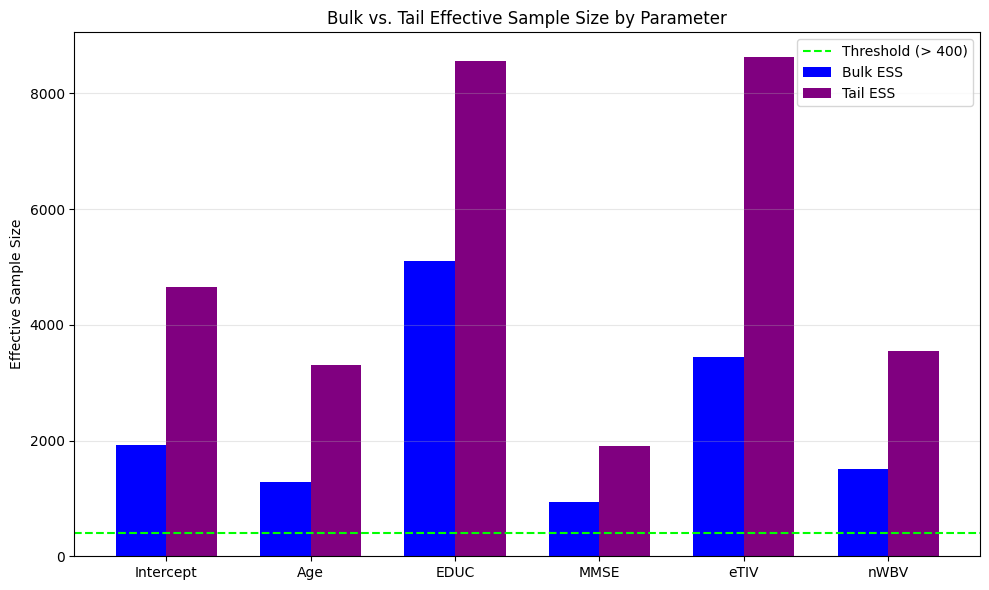

In [20]:
parameter_names  = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

x = np.arange(len(parameter_names))
width = 0.35

fig, ax = plt.subplots(figsize = (10, 6))
rects1 = ax.bar(x - width/2, bulk_ess, width, label = 'Bulk ESS', color = 'blue')
rects2 = ax.bar(x + width/2, tail_ess, width, label = 'Tail ESS', color = 'purple')

ax.axhline(y=400, color = 'lime', linestyle = '--', linewidth=1.5, label = 'Threshold (> 400)') #Shows the threshold lieene.

ax.set_ylabel('Effective Sample Size')
ax.set_title('Bulk vs. Tail Effective Sample Size by Parameter')
ax.set_xticks(x)
ax.set_xticklabels(parameter_names)
ax.legend()
ax.grid(axis = 'y', linestyle = '-', alpha = 0.3)

plt.tight_layout()
plt.show()

As illustrated by the grouped bar chart, all parameters comfortably exceed the 400 threshold for both Bulk and Tail Effective Sample Sizes. The Tail ESS values demonstrate an exceptional efficiency at the distribution boundaries.

### Rank Normalized Split:

The last major diagnostic to check is the Rank Normalized Split. Now the Gelman Rubin Diagnostic works well but has 2 major problems that the Rank Normalized Split fixes. The Standard R is blind to differences in distribution shape/tails and if a single chain starts in a low-probability region, spends half its time drifting upward, and eventually reaches equilibrium, its overall variance might mask the initial non-stationarity.The split rank test fixes said issues since it forces the chains into a common normal distribution space meaning all those differences in shapes/tails are easily seen and caught. It also cuts every chain in half, treating each half as an independent chain which in turn exposes whether a chain drifted or changed behavior over time.

In [21]:
def compute_rank_normalized_split_rhat(chains_3d):
    M, N, K = chains_3d.shape
    rhat_values = []
    
    half_N = N // 2
    split_chains = np.concatenate([
        chains_3d[:, :half_N, :],
        chains_3d[:, half_N:2 * half_N, :]
    ], axis=0)

#Just splits the chains into N/2 and M chains as 2M chains of N/2 length!     
    
    num_chains, len_chain, num_params = split_chains.shape
    S = num_chains * len_chain
    
    for k in range(num_params):
        param_matrix = split_chains[:, :, k] 
        flat = param_matrix.flatten()
        
        ranks = rankdata(flat, method='average')
        
#Computes the ranks. 
        
        normalized_flat = norm.ppf((ranks - 3.0 / 8.0) / (S + 0.25))

#This just the Normal quantile transformation aka Blom's score, this in turn allows us to see all those issues with tails etc.
#It maps the integer ranks to probabilities and norm translates them into standard normal z-scores which exposes discrepancies in scale and tail shape.
        
        z_matrix = normalized_flat.reshape(num_chains, len_chain)
        
        chain_means = np.mean(z_matrix, axis=1)
        overall_mean = np.mean(z_matrix)
        
        B = len_chain / (num_chains - 1) * np.sum((chain_means - overall_mean) ** 2)

#Gives the beteween variance of the chains.
        
        chain_vars = np.var(z_matrix, axis=1, ddof=1)
        W = np.mean(chain_vars)

#Gives the within variance of the chains.
        
        var_plus = ((len_chain - 1) / len_chain) * W + (1 / len_chain) * B

#Gives the marginal posterior variance.
        
        rhat = np.sqrt(var_plus / W)
        rhat_values.append(rhat)
        
    return rhat_values

#Pretty much, we split the chains so now we have more chains of shorter lengths. We transform it using a rank normalization called Blom's Score. 
#We just like before, calculate those variances(within, between,etc.) like Gelman Rubin and evaluate the end like Gelman Rubin. 
#The main difference is we just evaluate 2 parts of the chain + do a normalization quantile transformation.

rank_rhats = compute_rank_normalized_split_rhat(clean_multi_chains)
#Just like the other diagnostics I had to compute the r hat for all the chains.

rhat_df = pd.DataFrame({
    'Parameter': ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV'],
    'Rank-Normalized Split-Rhat': rank_rhats,
    'Status (< 1.01)': ['Converged' if r < 1.01 else 'Review' for r in rank_rhats]
})

rhat_df.round(4)

#Just made this to displkay the entire rhat splits for easy viewability.

,Parameter,Rank-Normalized Split-Rhat,Status (< 1.01)
0,Intercept,1.0034,Converged
1,Age,1.0029,Converged
2,EDUC,1.0007,Converged
3,MMSE,1.0064,Converged
4,eTIV,1.0028,Converged
5,nWBV,1.0043,Converged


## Multi-Trace Plot:

Now that mathematical proof has been shown for the convergence of the multiple chains, it is important that there's visual proof indicating we haven't messed up anywhere. Thus, below, we can perform a multi-chain trace plotting to check if everything is visually verified.

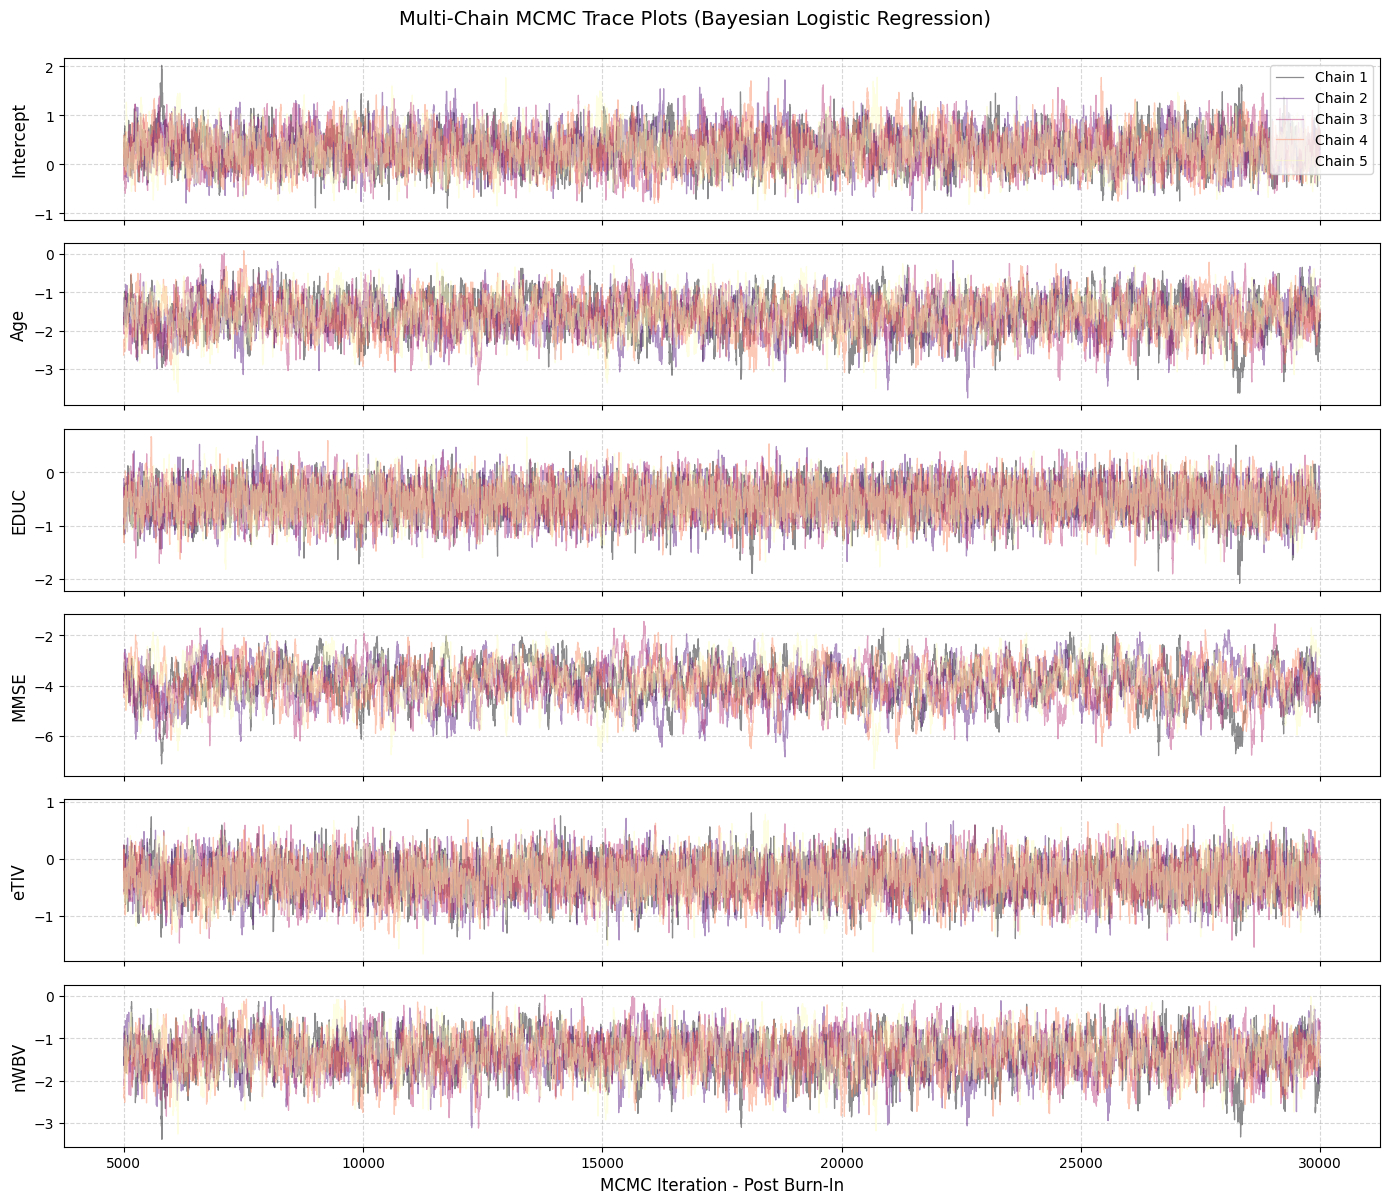

In [22]:
def plot_multichain_traces(multi_chains, feature_names, burn_in = 5000):
  num_chains, num_samples, num_params = multi_chains.shape
  iterations = np.arange(burn_in, num_samples)
    
#Instead of handdoing all the numbers, I just decided to fit them using .shape so it scales that way. 
#The iterataions section creates an array of the actual iteration numbers for display and only keeps the post burn-in samples so everything lines up properly.
    
  fig, axes = plt.subplots(num_params, 1, figsize = (14, 2 * num_params), sharex = True)

#Added some dynamic sizing so that it fits to the number of parameters I am using which in my case here is just 6, but if I wanted to add more it just saves me some time.
    
  colors = plt.cm.magma(np.linspace(0, 1, num_chains))

#Chose magma so each trace of the chains were distinct. Viridis was a second option but I felt magma was much easier to visualize.

  for a in range(num_params):
    ax = axes[a] if num_params > 1 else axes
      
    for b in range(num_chains):
      chain_slice = multi_chains[b, burn_in:, a]
      ax.plot(
          iterations,
          chain_slice,
          color = colors[b],
          alpha = 0.45,
          lw = 0.9,
          label = f"Chain {b+1}" if a == 0 else "",
      )
        
#So looping through each parameter a in # of parameters while b loops through each chain! Thusssssss, everything is accounted for and I chose the transparency/alpha to be somewhat translucent since I wanted the chains to still be distinctly visible.
    
    ax.set_ylabel(
        f"{feature_names[a]}", fontsize = 12
    )
    ax.grid(True, linestyle="--", alpha = 0.5)

    if a == 0:
      ax.legend(loc="upper right", frameon = True)

  axes[-1].set_xlabel("MCMC Iteration - Post Burn-In", fontsize = 12)
  fig.suptitle(
      "Multi-Chain MCMC Trace Plots (Bayesian Logistic Regression)",
      fontsize = 14,
      y = 1,
  )
  plt.tight_layout()
  plt.show()

#Everything else here is just basic graphing stuff for the titles, positioning etc.

parameter_names = ['Intercept'] + features

#This combines the string 'Intercept' with my  features list so that the names align with the columns in the model. The part below obviously just plots it.

plot_multichain_traces(multi_chains, parameter_names, burn_in = 5000)

## Cross-Validation with PyMC:

While convergence diagnostics like before with Gelman Rubin and high Bulk/Tail Effective Sample Size, along with the multi-chain trace plots confirm that my custom Metropolis-Hastings  are mixed well and stabilized, said convergence does not necessarily guarantee that everything is correct. This is especially evident since I'm doing it from scratch. For example, a flawed log-posterior implementation or subtle scaling bugs can lead to a sampler converging to the a false mathematical target distribution. Thus, to verify whether it's correct or not, I need to see how it fairs in comparison with its draws against PyMC's No-U-Turn Sampler (NUTS), which is just an automated Hamiltonian Monte Carlo algorithm. I know Stan is also a fair option for comparison but I'm choosing PyMC due to it not requiring any C++ compilers etc.

In [23]:
with pm.Model() as pymc_model:
  beta = pm.Normal("beta", mu = 0, sigma = 10, shape = X.shape[1])

#Since PyMC uses a context manager to build a probabilistic graphical model, rverything indented under this block is automatically registered as part of the statistical model.
#The mean is centered at 0 and the std is 10 so that there's a weakly informative prior and thus allows the data to dominate the posterior while keeping the sampler numerically stable.
#The shape also just dynamically creates a vector of coefficients matching the exact number of columns in the design matrix.
    
  linear_pred = pm.math.dot(X, beta)

#The standard linear combination for regression is η = Xβ, hence why it's written as such. 
    
  obs = pm.Bernoulli("obs", logit_p = linear_pred, observed = y)

#Using Bernoulli likilhood here and applying the sigmoid function here to map the linear predictor over to a probability.

  pymc_trace = pm.sample(
      draws = 5000, tune = 2000, chains = 5, return_inferencedata = True
  )

#This just attaches the model to my actual data and tells PyMC which values to condition on when calculating the posterior. 
#

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (5 chains in 4 jobs)
NUTS: [beta]


Output()

Sampling 5 chains for 2_000 tune and 5_000 draw iterations (10_000 + 25_000 draws total) took 15 seconds.


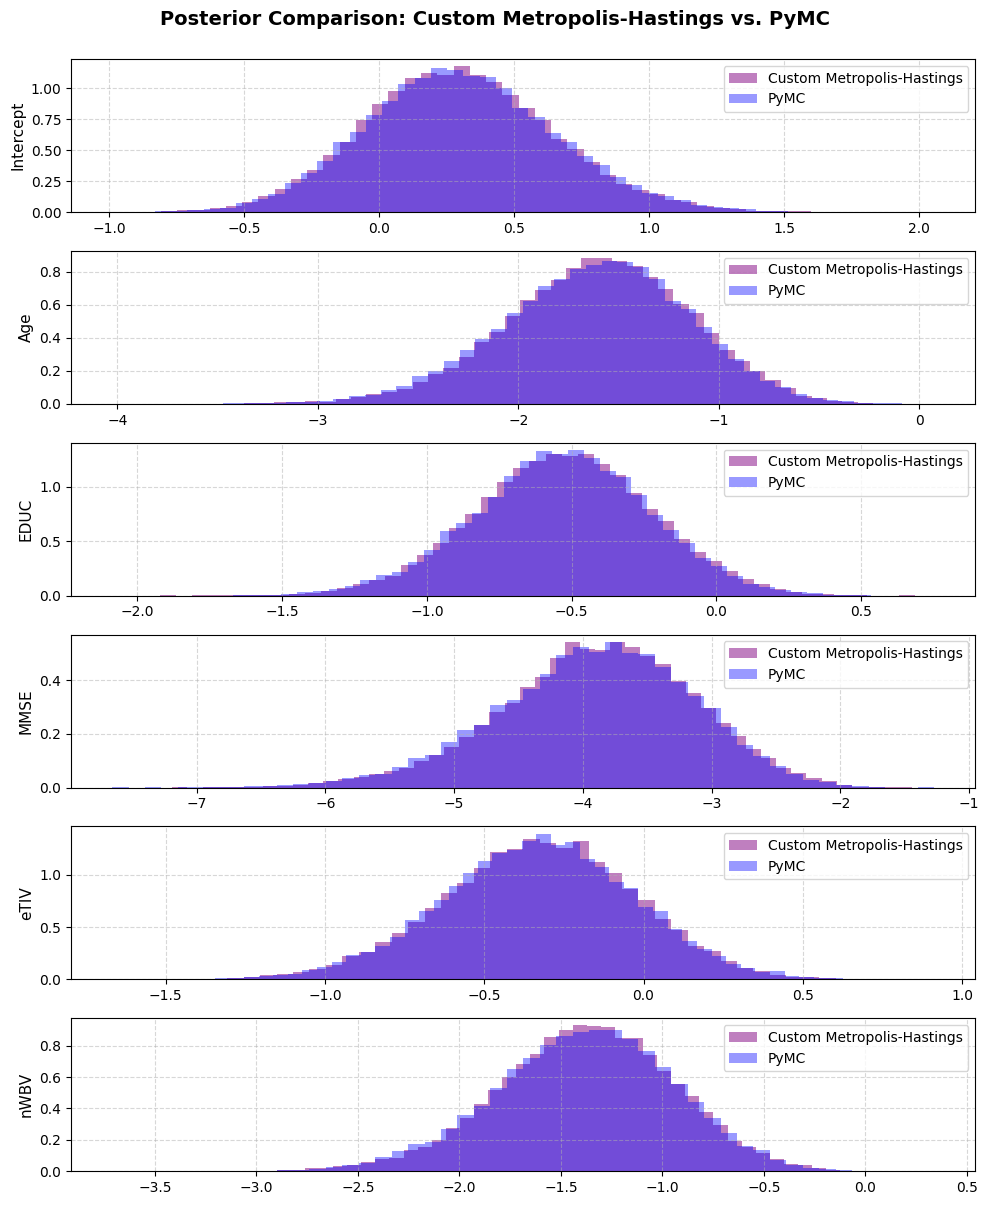

In [24]:
num_params = multi_chains.shape[2]

#Gives the number of parameters such that we can get the number of plots.

fig, axes = plt.subplots(num_params, 1, figsize = (10, 2 * num_params))

for p in range(num_params):
  ax = axes[p] if num_params > 1 else axes  
    
  custom_samples = multi_chains[:, 5000:, p].flatten() 
  pymc_samples = pymc_trace.posterior["beta"].values[:, :, p].flatten()

#Just loops through the parameters, slices the array into chains, drops in the burn-in period which i s 5000 in my case and merges them with the flatten method. 

  ax.hist(
      custom_samples,
      bins = 50,
      density = True,
      alpha = 0.5,
      color = "purple",
      label = "Custom Metropolis-Hastings",
  )
  ax.hist(
      pymc_samples,
      bins = 50,
      density = True,
      alpha = 0.4,
      color = "blue",
      label = "PyMC",
  )

  ax.set_ylabel(parameter_names[p], fontsize = 11)
  ax.legend(loc = "upper right")
  ax.grid(True, linestyle="--", alpha = 0.5)

fig.suptitle(
    "Posterior Comparison: Custom Metropolis-Hastings vs. PyMC",
    fontsize = 14,
    fontweight = "bold",
    y = 1,
)
plt.tight_layout()
plt.show()

#Everything else is just graphing stuff/aligning of labels etc.

As shown, it is abundantly clear that my custom Metropolis-Hastings MCMC sampler fits pretty accurately to PyMC's implementation. Therefore, it's pretty safe to say that I landed on the correct mathematical target distribution. Now all that's left is to look at the Marginal posterior distributions and interpret it.

## Posterior Inference & Clinical Interpretation:

Now that all the diagnostics have run and are valid across multiple tests, it is time to pool the data together and interpret the entire post burn-in samples.

In [25]:
parameter_names = ['Intercept', 'Age', 'EDUC', 'MMSE', 'eTIV', 'nWBV']

flat_chains = clean_multi_chains.reshape(-1, clean_multi_chains.shape[2])
#Flattens the chains since earlier with the diagnostics it is statistically robust meaning we can just pool them all together.

final_summary = []

for i, name in enumerate(parameter_names):
    samples = flat_chains[:, i]
    
    post_mean = np.mean(samples)
    post_std = np.std(samples)
    ci_lower = np.percentile(samples, 2.5)
    ci_upper = np.percentile(samples, 97.5)
    odds_ratio = np.exp(post_mean)
    
    final_summary.append({
        'Parameter': name,
        'Posterior Mean': post_mean,
        'Posterior Std': post_std,
        '95% Credible Lower': ci_lower,
        '95% Credible Upper': ci_upper,
        'Odds Ratio exp': odds_ratio
    })

inference_df = pd.DataFrame(final_summary)
inference_df.round(3)

,Parameter,Posterior Mean,Posterior Std,95% Credible Lower,95% Credible Upper,Odds Ratio exp
0,Intercept,0.297,0.348,-0.360,1.016,1.345
1,Age,-1.602,0.460,-2.554,-0.747,0.202
2,EDUC,-0.529,0.307,-1.144,0.064,0.589
3,MMSE,-3.888,0.754,-5.507,-2.509,0.020
4,eTIV,-0.329,0.302,-0.937,0.243,0.720
5,nWBV,-1.379,0.434,-2.276,-0.562,0.252


### Interpretations:

* An Odds Ratio > 1 indicates the predictor increases the odds of dementia.
* An Odds Ratio < 1 indicates the predictor decreases the odds of dementia.
* An Odds Ratio = 1 indicates no effect on dementia by the predictor. 

This indicates that in terms of dementia reduction, MMSE and nWBV are the dominant protective predictors. Age has a significant Odds Ratio, though in this specific longitudinal cohort, sample conditioning causes it to appear protective, despite clinical literature showing age as a core risk factor for Alzheimer's progression.

The posterior mean provides our point estimates for the log-odds coefficients and posterior standard deviation quantify the epistemic uncertainty of our parameter estimates. The posterior mean here just indicates the predictive power and strength of the predictor in the model. Thus by taking the absolute values of those posterior means, we find the magnitude of all of them indicates that MMSE has the strongest predictive power in the model. The posterior standard deviation here indicates the spread and thus the clarity of the values. As a result, the smaller the posterior standard deviation, the better the clarity of the values from that predictor. Therefore, EDUC and eTIV from a first look have some of the best clarities amongst the predictors but are instead precisely zero/inconclusive due to their posterior standard deviations being nearly equivalent to the magnitude of the posterior means.
\
\
Now the important thing to note is how both the posterior mean and standard deviation interact, if the magnitude of the posterior mean compared to the posterior standard deviation is high, then there's a large predictive power while also having a relatively good clarity since the spread would be much tighter, thus looking for these predictors would be most helpful for dementia prediction.

**Best Predictors:** 
* MMSE: μ = -3.888 vs. σ = 0.754, meaning it has a high signal with a tight spread/high clarity.
* Age: μ = -1.602 vs. σ = 0.460, meaning it has a medium signal with a very tight spread/very high clarity.
* nWBV: μ = -1.379 vs. σ = 0.434, meaning it has a medium signal with a very tight spread/very high clarity. 